# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** I Gede Wastu Namsa Raditya
- **Email:** ds014b6y0750@student.devacademy.id
- **ID Dicoding:** ds014b6y0750

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1** Siapa saja pelanggan terbaik kita jika dilihat dari kapan terakhir mereka belanja, seberapa sering, dan seberapa besar pengeluarannya? (Analisis RFM)
- **Pertanyaan 2:** Wilayah atau negara bagian mana sih yang memberikan pemasukan (revenue) paling besar buat e-commerce ini?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='darkgrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
customers_df = pd.read_csv("customers_dataset.csv")
orders_df = pd.read_csv("orders_dataset.csv")
order_payments_df = pd.read_csv("order_payments_dataset.csv")

print("=== Customers Dataset ===")
display(customers_df.head())

print("\n=== Orders Dataset ===")
display(orders_df.head())

print("\n=== Order Payments Dataset ===")
display(order_payments_df.head())

=== Customers Dataset ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



=== Orders Dataset ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



=== Order Payments Dataset ===


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


**Insight:** (Opsional)
- Tiga dataset berhasil dimuat: customers_dataset.csv (berisi data geografi pelanggan), orders_dataset.csv (berisi status dan waktu pesanan), serta order_payments_dataset.csv (berisi nilai dan metode pembayaran).
- Ketiga tabel ini saling berhubungan dan dapat digabungkan (merge) nantinya menggunakan kunci customer_id dan order_id.

### Assessing Data

#### Identifying ... problem
- Mengubah seluruh tipe data pada kolom yang merepresentasikan waktu di tabel orders_df (seperti order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, dan order_estimated_delivery_date) dari tipe object (string) menjadi tipe datetime agar valid untuk operasi deret waktu.

- Memfilter tabel orders_df untuk membuang pesanan yang gagal/dibatalkan dan hanya menyisakan baris data dengan order_status bernilai 'delivered' demi menjaga keakuratan analisis perhitungan pendapatan.

In [3]:
print("1. Info Customers Dataset:")
customers_df.info()
print("\nJumlah duplikasi Customers:", customers_df.duplicated().sum())

print("\n2. Info Orders Dataset:")
orders_df.info()
print("\nJumlah duplikasi Orders:", orders_df.duplicated().sum())

print("\n3. Info Order Payments Dataset:")
order_payments_df.info()
print("\nJumlah duplikasi Order Payments:", order_payments_df.duplicated().sum())

1. Info Customers Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

Jumlah duplikasi Customers: 0

2. Info Orders Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   9

**Steps to Take:**

**Insight:** (Opsional)

- Ketiga tabel ini tidak memiliki data duplikat, bisa dilihat dari output masing-masing tabel, semuanya memiliki output 0
- Terdapat tipe data yang tidak sesuai pada tabel orders_df, yaitu kolom yang merepresentasikan waktu (seperti order_purchase_timestamp dan order_delivered_customer_date) masih terbaca sebagai teks/string (object), bukan sebagai tipe waktu (datetime).
- Ditemukan missing values (data kosong) pada kolom tanggal pengiriman di tabel orders_df, yang wajar terjadi karena adanya pesanan yang statusnya belum terkirim atau dibatalkan.

### Cleaning Data

#### Fixing ... problem

In [4]:
datetime_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in datetime_columns:
    orders_df[column] = pd.to_datetime(orders_df[column], errors='coerce')

print("Tipe data setelah diperbaiki:\n", orders_df.dtypes)

orders_df = orders_df[orders_df['order_status'] == 'delivered']
print("\nJumlah baris pesanan 'delivered':", orders_df.shape[0])

Tipe data setelah diperbaiki:
 order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Jumlah baris pesanan 'delivered': 96478


**Insight:** (Opsional)
- Seluruh kolom waktu pada tabel orders_df telah berhasil diubah ke format datetime64[ns] agar dapat digunakan untuk operasi perhitungan waktu nantinya.

- Data telah difilter secara spesifik untuk hanya menyertakan pesanan dengan status berhasil terkirim ('delivered'). Proses ini menyusutkan jumlah baris dari 99.441 menjadi 96.478 pesanan yang valid untuk analisis pendapatan.

## Exploratory Data Analysis (EDA)

### Explore ...

In [5]:
orders_customers_df = pd.merge(
    left=orders_df,
    right=customers_df,
    how="left",
    left_on="customer_id",
    right_on="customer_id"
)

all_df = pd.merge(
    left=orders_customers_df,
    right=order_payments_df,
    how="left",
    left_on="order_id",
    right_on="order_id"
)

print("=== Preview Data Gabungan (all_df) ===")
display(all_df.head())

print("\n=== Info Data Gabungan ===")
all_df.info()

=== Preview Data Gabungan (all_df) ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,credit_card,3.0,179.12



=== Info Data Gabungan ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100757 entries, 0 to 100756
Data columns (total 16 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       100757 non-null  object        
 1   customer_id                    100757 non-null  object        
 2   order_status                   100757 non-null  object        
 3   order_purchase_timestamp       100757 non-null  datetime64[ns]
 4   order_approved_at              100743 non-null  datetime64[ns]
 5   order_delivered_carrier_date   100755 non-null  datetime64[ns]
 6   order_delivered_customer_date  100749 non-null  datetime64[ns]
 7   order_estimated_delivery_date  100757 non-null  datetime64[ns]
 8   customer_unique_id             100757 non-null  object        
 9   customer_zip_code_prefix       100757 non-null  int64         
 10  customer_city                  100757 no

**Insight:** (Opsional)
- Tabel pesanan, pelanggan, dan pembayaran telah berhasil digabungkan menjadi satu DataFrame utama bernama all_df.

- Data gabungan ini kini berisi informasi komprehensif yang menghubungkan identitas pelanggan (customer_unique_id), lokasi asal pelanggan (customer_state), waktu transaksi (order_purchase_timestamp), hingga nominal pembayaran (payment_value). Data ini sudah sangat siap untuk dieksekusi dalam proses RFM Analysis dan Geoanalysis.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

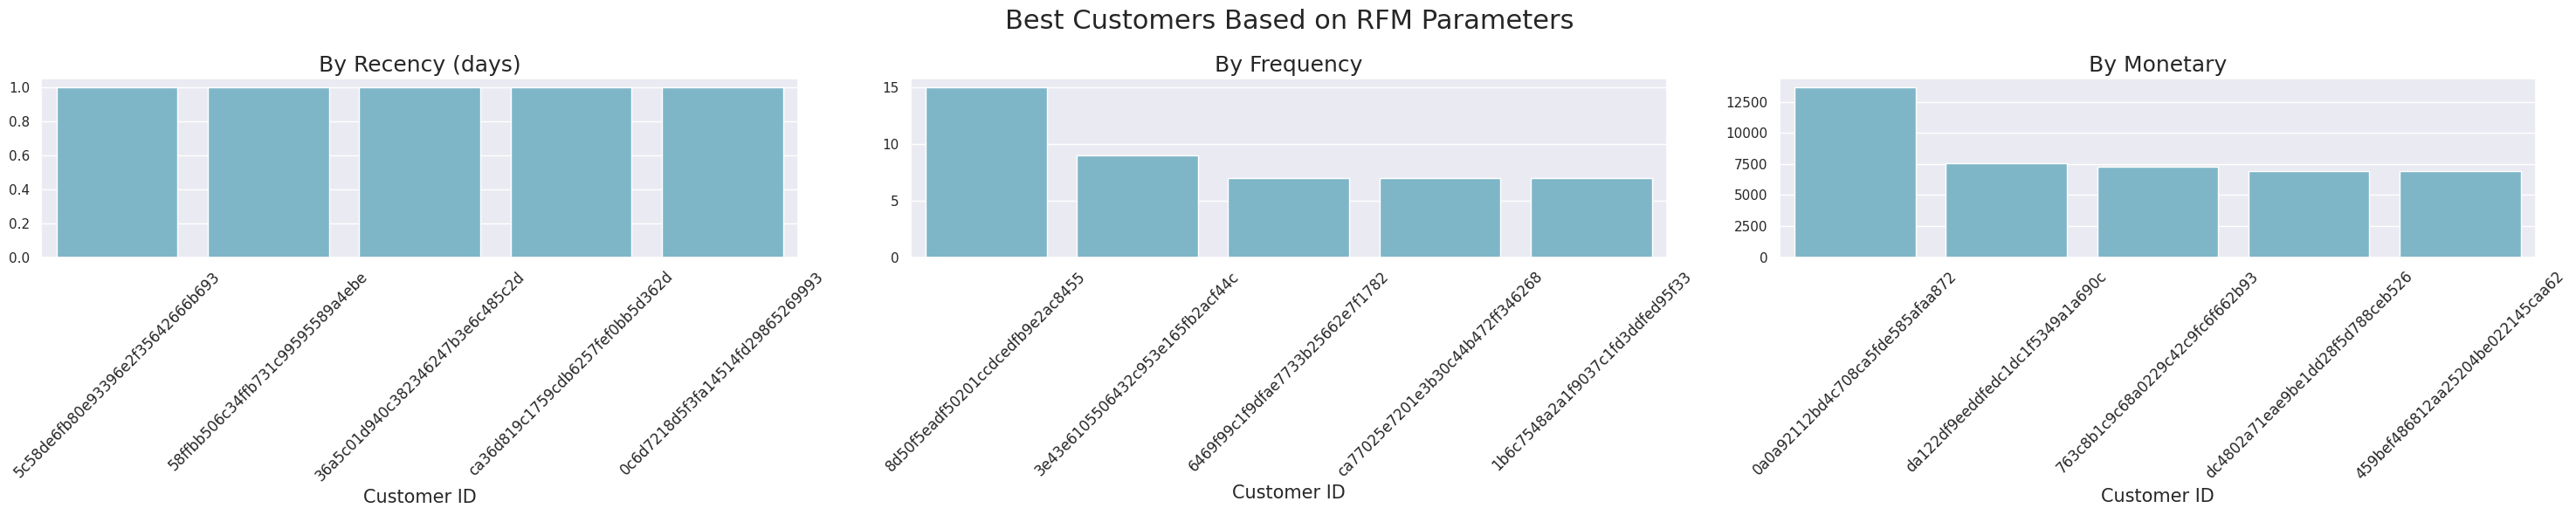

In [6]:
recent_date = all_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = all_df.groupby("customer_unique_id", as_index=False).agg({
    "order_purchase_timestamp": lambda x: (recent_date - x.max()).days, # Recency ni jarak hari dari transaksi terakhir
    "order_id": "nunique", # Frequency ni jumlah transaksi unik
    "payment_value": "sum" # Monetary ni total uang yang dihabiskan
})

rfm_df.columns = ["customer_unique_id", "recency", "frequency", "monetary"]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(30, 6))
colors = ["#72BCD4", "#72BCD4", "#72BCD4", "#72BCD4", "#72BCD4"]

sns.barplot(
    y="recency", x="customer_unique_id",
    data=rfm_df.sort_values(by="recency", ascending=True).head(5),
    palette=colors, hue="customer_unique_id", legend=False, ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Customer ID", fontsize=15)
ax[0].set_title("By Recency (days)", loc="center", fontsize=18)
ax[0].tick_params(axis ='x', labelsize=12, rotation=45)

sns.barplot(
    y="frequency", x="customer_unique_id",
    data=rfm_df.sort_values(by="frequency", ascending=False).head(5),
    palette=colors, hue="customer_unique_id", legend=False, ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Customer ID", fontsize=15)
ax[1].set_title("By Frequency", loc="center", fontsize=18)
ax[1].tick_params(axis='x', labelsize=12, rotation=45)

sns.barplot(
    y="monetary", x="customer_unique_id",
    data=rfm_df.sort_values(by="monetary", ascending=False).head(5),
    palette=colors, hue="customer_unique_id", legend=False, ax=ax[2]
)
ax[2].set_ylabel(None)
ax[2].set_xlabel("Customer ID", fontsize=15)
ax[2].set_title("By Monetary", loc="center", fontsize=18)
ax[2].tick_params(axis='x', labelsize=12, rotation=45)

plt.suptitle("Best Customers Based on RFM Parameters", fontsize=22)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

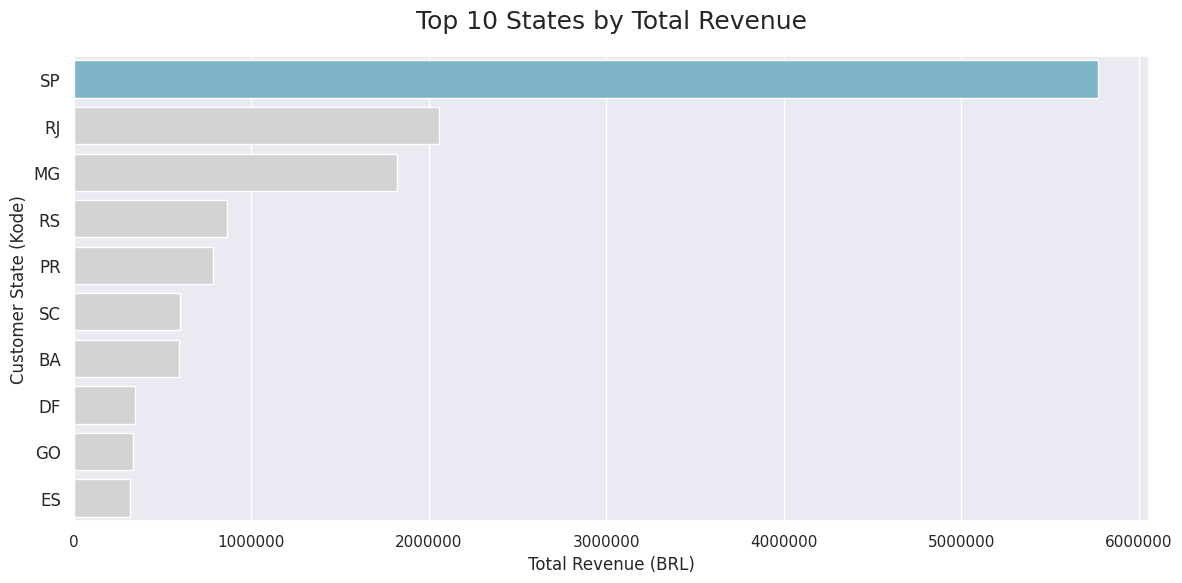

In [7]:
state_revenue_df = all_df.groupby(by="customer_state").agg({
    "payment_value": "sum"
}).sort_values(by="payment_value", ascending=False).reset_index()

plt.figure(figsize=(12, 6))

colors_state = ["#72BCD4" if i == 0 else "#D3D3D3" for i in range(len(state_revenue_df.head(10)))]

sns.barplot(
    x="payment_value",
    y="customer_state",
    data=state_revenue_df.head(10),
    palette=colors_state,
    hue="customer_state",
    legend=False
)

plt.title("Top 10 States by Total Revenue", loc="center", fontsize=18, pad=20)
plt.ylabel("Customer State (Kode)", fontsize=12)
plt.xlabel("Total Revenue (BRL)", fontsize=12)
plt.tick_params(axis='y', labelsize=12)
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Recency & Frequency: Sebagian besar basis pelanggan cenderung hanya melakukan satu kali transaksi. Namun, kita memiliki kelompok pelanggan setia yang transaksi terakhirnya masih sangat baru (Recency rendah) dan berbelanja lebih dari satu kali.

- Monetary: Distribusi pendapatan ternyata sangat terpusat. Segelintir pelanggan VIP di puncak grafik menyumbang total pengeluaran (Monetary) yang jauh melampaui rata-rata pelanggan lainnya. Hal ini membuktikan bahwa kesehatan finansial bisnis sangat bergantung pada strategi retensi untuk menjaga kelompok kecil ini agar tidak kabur ke kompetitor.

- Dominasi Wilayah: Negara bagian Sao Paulo (SP) merupakan pasar paling krusial, menyumbang total pendapatan (revenue) tertinggi secara mutlak dibandingkan seluruh wilayah lainnya.

- Kesenjangan (Gap) Pasar: Meskipun Rio de Janeiro (RJ) dan Minas Gerais (MG) menempati posisi kedua dan ketiga, margin pendapatannya terlampau sangat jauh di bawah SP. Hal ini mengindikasikan bahwa penetrasi pasar dan infrastruktur e-commerce saat ini sangat terpusat di SP, sementara wilayah lain masih belum digarap secara maksimal dan memiliki potensi ekspansi yang besar.

## Analisis Lanjutan (Opsional)

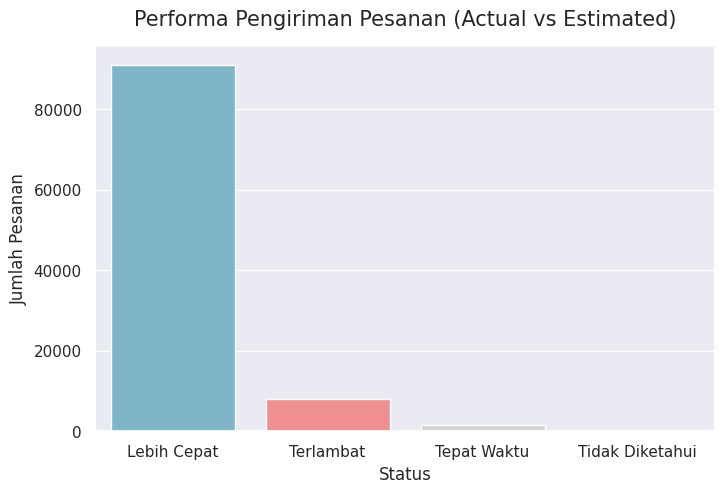

In [8]:
all_df['delivery_time_diff'] = (all_df['order_estimated_delivery_date'] - all_df['order_delivered_customer_date']).dt.days

def categorize_delivery(diff):
    if pd.isna(diff):
        return "Tidak Diketahui"
    elif diff > 0:
        return "Lebih Cepat"
    elif diff == 0:
        return "Tepat Waktu"
    else:
        return "Terlambat"

all_df['delivery_performance'] = all_df['delivery_time_diff'].apply(categorize_delivery)

delivery_stats = all_df['delivery_performance'].value_counts().reset_index()
delivery_stats.columns = ['Status Pengiriman', 'Jumlah Pesanan']

plt.figure(figsize=(8, 5))
colors_delivery = ["#72BCD4", "#FF7F7F", "#D3D3D3", "#FFE066"]

sns.barplot(
    x='Status Pengiriman',
    y='Jumlah Pesanan',
    data=delivery_stats,
    palette=colors_delivery,
    hue='Status Pengiriman',
    legend=False
)

plt.title("Performa Pengiriman Pesanan (Actual vs Estimated)", fontsize=15, pad=15)
plt.ylabel("Jumlah Pesanan", fontsize=12)
plt.xlabel("Status", fontsize=12)
plt.show()

**Insight:** (Opsional)
- Mayoritas pesanan tiba "Lebih Cepat" dari tanggal estimasi yang dijanjikan kepada pelanggan. Ini menunjukkan bahwa sistem logistik dan operasional e-commerce secara umum berjalan dengan sangat efisien.

- Meskipun demikian, masih terdapat sejumlah pesanan yang berstatus "Terlambat". Angka keterlambatan ini bisa menjadi acuan evaluasi bagi tim logistik atau pihak kurir rekanan (ekspedisi) agar tidak menurunkan tingkat kepuasan pelanggan (Customer Satisfaction).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pelanggan terbaik diidentifikasi berdasarkan Recency yang rendah, serta Frequency dan Monetary yang sangat tinggi dibandingkan mayoritas pelanggan lain yang hanya bertransaksi satu kali.

- **Conclusion pertanyaan 2:** Sao Paulo (SP) adalah negara bagian penyumbang total pendapatan (Revenue) tertinggi secara signifikan, jauh melampaui wilayah lain seperti Rio de Janeiro (RJ) dan Minas Gerais (MG).

**Rekomendasi Action Item:**
- Terapkan program loyalitas: Berikan penawaran eksklusif kepada kelompok Top Customers (berdasarkan nilai RFM tinggi) untuk mempertahankan retensi, mengingat mereka menyumbang porsi pendapatan yang besar meskipun jumlahnya kecil.

- Optimalkan infrastruktur logistik di Sao Paulo (SP): Pertahankan dan tingkatkan efisiensi pengiriman di wilayah ini sebagai basis pendapatan utama.

- Buat kampanye pemasaran berjenjang: Rancang subsidi ongkos kirim atau promo khusus untuk menstimulasi pertumbuhan penjualan di wilayah menengah seperti RJ dan MG agar potensinya lebih maksimal.

In [9]:
all_df.to_csv("all_data.csv", index=False)